# Experiment No. 10 (Computer Laboratory – I BE AI&DS)

**Aim:** Data Visualization using matplotlib  
**Problem Statement:** Analyzing Air Quality Index (AQI) Trends in a City  
**Dataset:** `"City_Air_Quality.csv"`  

**Tasks to Perform:**
1. Import the "City_Air_Quality.csv" dataset.
2. Explore the dataset to understand its structure and content.
3. Identify the relevant variables for visualizing AQI trends (date, pollutant levels, AQI values).
4. Create line plots or time series plots to visualize the overall AQI trend over time.
5. Plot individual pollutant levels (PM2.5, PM10, CO, NO2) on separate line plots over time.
6. Use bar plots and stacked bar plots to compare AQI values across different dates or months.
7. Create box plots to analyze the distribution of AQI values across different pollutant categories.
8. Use scatter plots and bubble charts to explore the relationship between AQI values and pollutant levels.
9. Customize visualizations by adding labels, titles, legends, reference thresholds, and appropriate color schemes.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Import dataset
df = pd.read_csv("City_Air_Quality.csv")

# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Explore dataset
print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

# Relevant variables
print("\nVariables for Visualization:")
print("Date, AQI, PM2.5, PM10, CO, NO2")

Dataset Shape: (120, 8)


,Date,City,PM2.5,PM10,CO,NO2,AQI,AQI_Category
0,2023-01-01,Pune,102.5,200.3,1.78,59.9,137,Moderate
1,2023-01-02,Pune,92.7,148.7,1.91,65.1,118,Moderate
2,2023-01-03,Pune,103.9,215.1,2.18,55.3,127,Moderate
3,2023-01-04,Pune,116.1,180.9,2.39,63.0,158,Moderate
4,2023-01-05,Pune,88.4,170.9,1.55,57.0,113,Moderate



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Date          120 non-null    datetime64[us]
 1   City          120 non-null    str           
 2   PM2.5         120 non-null    float64       
 3   PM10          120 non-null    float64       
 4   CO            120 non-null    float64       
 5   NO2           120 non-null    float64       
 6   AQI           120 non-null    int64         
 7   AQI_Category  120 non-null    str           
dtypes: datetime64[us](1), float64(4), int64(1), str(2)
memory usage: 9.0 KB

Statistical Summary:


,Date,PM2.5,PM10,CO,NO2,AQI
count,120,120.000000,120.000000,120.000000,120.000000,120.000000
mean,2023-03-01 12:00:00,59.358333,109.506667,1.677167,43.300000,80.500000
min,2023-01-01 00:00:00,15.000000,30.000000,0.520000,19.100000,30.000000
25%,2023-01-30 18:00:00,35.500000,64.175000,1.410000,32.275000,40.750000
50%,2023-03-01 12:00:00,55.000000,101.850000,1.680000,43.400000,73.500000
75%,2023-03-31 06:00:00,86.725000,148.825000,1.942500,53.100000,116.250000
max,2023-04-30 00:00:00,125.200000,251.700000,2.430000,83.200000,172.000000
std,NaN,30.287320,56.160897,0.365739,13.507664,39.294621



Variables for Visualization:
Date, AQI, PM2.5, PM10, CO, NO2


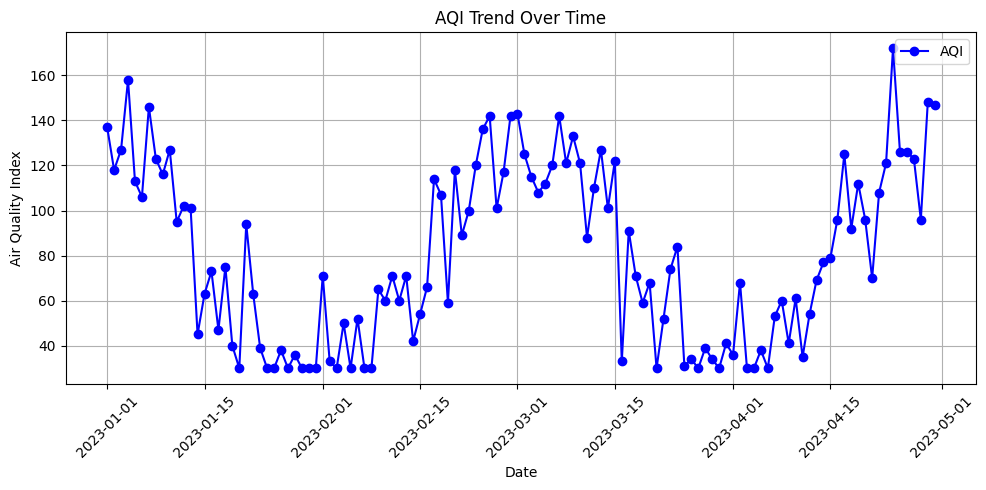

In [3]:
plt.figure(figsize=(10, 5))

plt.plot(df['Date'], df['AQI'], marker='o', color='blue', label='AQI')

plt.title("AQI Trend Over Time")
plt.xlabel("Date")
plt.ylabel("Air Quality Index")
plt.legend()
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

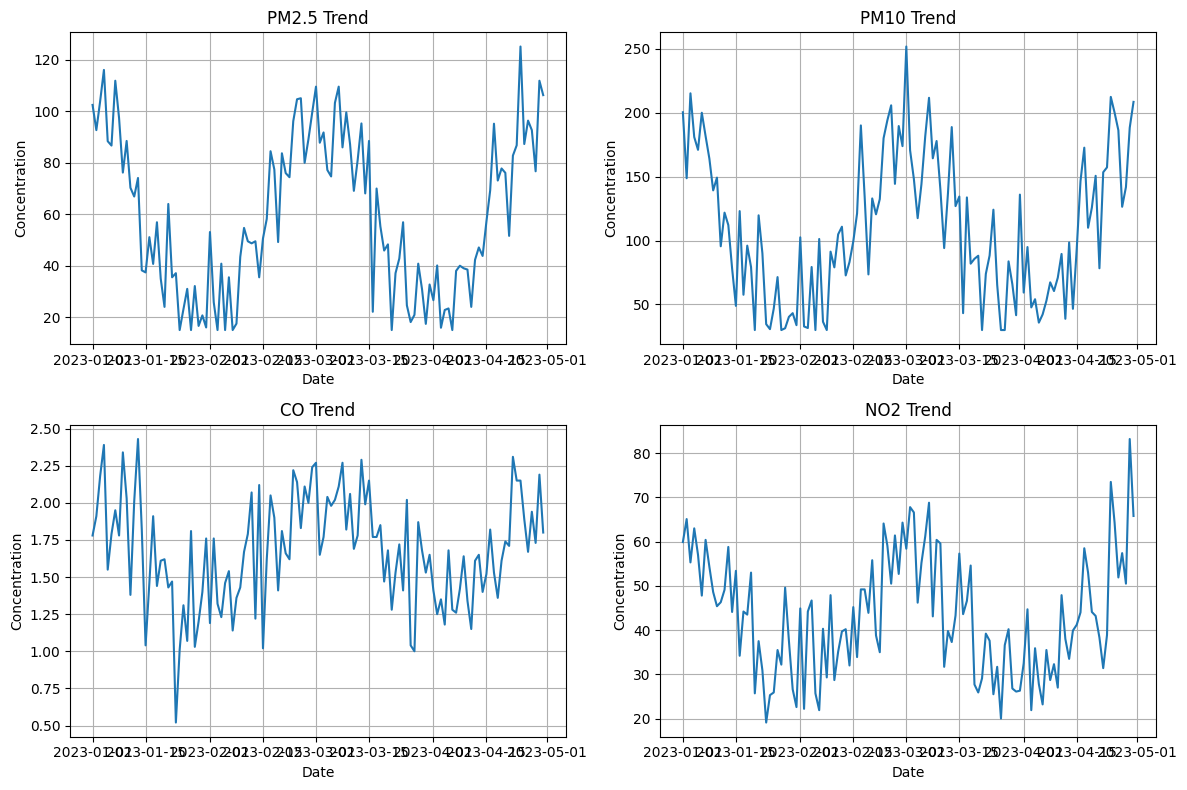

In [4]:
pollutants = ['PM2.5', 'PM10', 'CO', 'NO2']

plt.figure(figsize=(12, 8))

for i, col in enumerate(pollutants, 1):
    plt.subplot(2, 2, i)
    plt.plot(df['Date'], df[col])
    plt.title(col + " Trend")
    plt.xlabel("Date")
    plt.ylabel("Concentration")
    plt.grid(True)

plt.tight_layout()
plt.show()

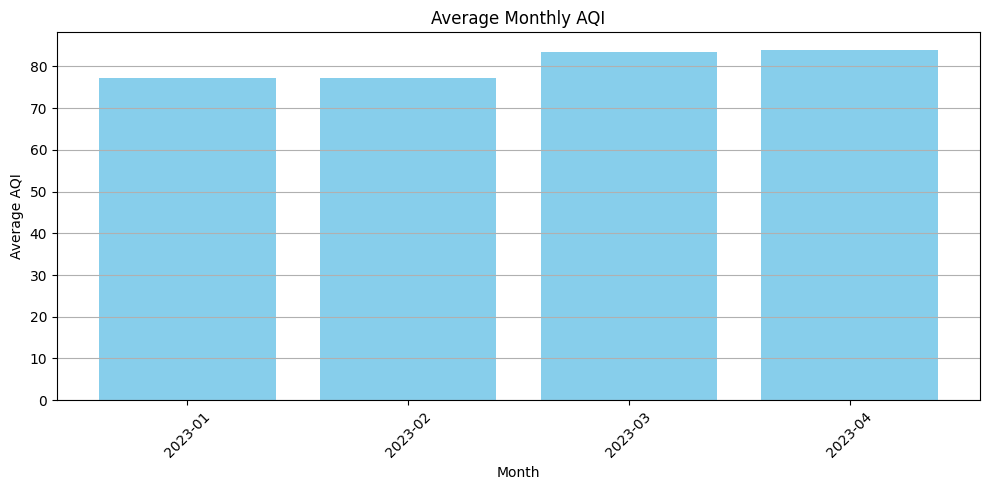

In [5]:
df['Month'] = df['Date'].dt.to_period('M')

monthly_aqi = df.groupby('Month')['AQI'].mean()

plt.figure(figsize=(10, 5))

plt.bar(monthly_aqi.index.astype(str), monthly_aqi.values, color='skyblue')

plt.title("Average Monthly AQI")
plt.xlabel("Month")
plt.ylabel("Average AQI")
plt.xticks(rotation=45)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

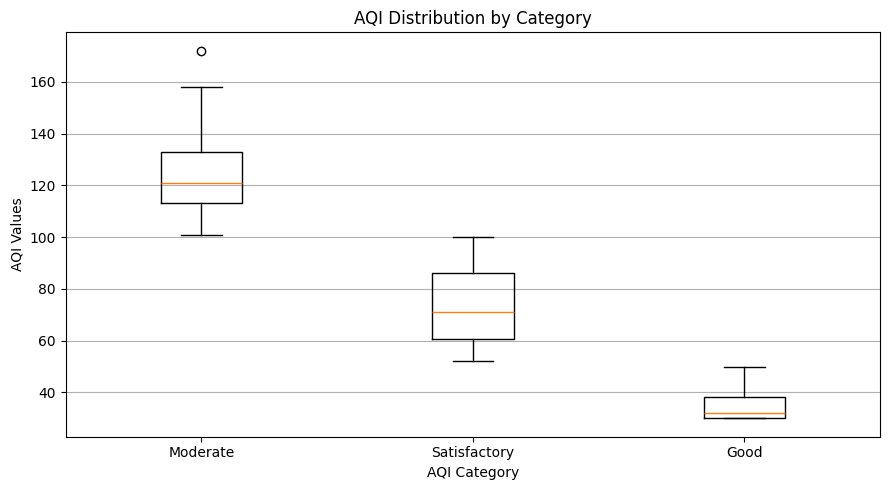

In [6]:
categories = df['AQI_Category'].dropna().unique()

box_data = [
    df[df['AQI_Category'] == category]['AQI'].dropna()
    for category in categories
]

plt.figure(figsize=(9, 5))

plt.boxplot(box_data, tick_labels=categories)

plt.title("AQI Distribution by Category")
plt.xlabel("AQI Category")
plt.ylabel("AQI Values")
plt.grid(axis='y')

plt.tight_layout()
plt.show()

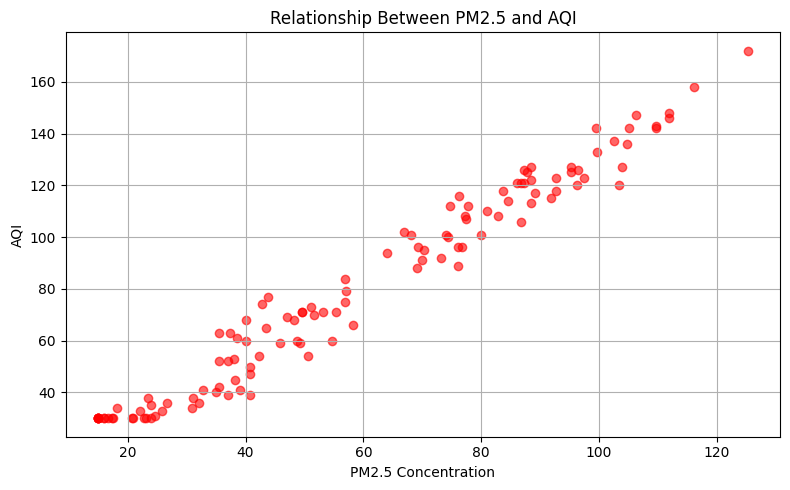

In [7]:
plt.figure(figsize=(8, 5))

plt.scatter(df['PM2.5'], df['AQI'], color='red', alpha=0.6)

plt.title("Relationship Between PM2.5 and AQI")
plt.xlabel("PM2.5 Concentration")
plt.ylabel("AQI")
plt.grid(True)

plt.tight_layout()
plt.show()